# Tugas UTS Machine Learning
**Mata Kuliah:** Machine Learning

## Identitas Mahasiswa
- **Nama:** Rayhan Eka Putra
- **NIM:** 241011400700
- **Kelas:** Reg B 


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 100
np.random.seed(RANDOM_STATE)

def train_test_split(X, y, test_size=0.25, random_state=100):
    """Membagi data secara acak dengan NumPy; test set diambil dari permutasi awal."""
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("X dan y harus memiliki jumlah baris yang sama.")
    if not 0 < test_size < 1:
        raise ValueError("test_size harus di antara 0 dan 1.")
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

class LinearRegression:
    """Linear Regression menggunakan normal equation dan NumPy."""
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        X_bias = np.c_[np.ones(len(X)), X]
        theta = np.linalg.pinv(X_bias.T @ X_bias) @ X_bias.T @ y
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.coef_ + self.intercept_

class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        self.x_mean = X.mean(axis=0)
        self.x_std = X.std(axis=0)
        self.x_std[self.x_std == 0] = 1
        Xs = (X - self.x_mean) / self.x_std
        self.y_mean = y.mean()
        self.y_std = y.std() if y.std() != 0 else 1
        ys = (y - self.y_mean) / self.y_std
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        self.loss_history = []
        for _ in range(self.n_iterations):
            pred = Xs @ self.weights + self.bias
            error = pred - ys
            self.loss_history.append(float(np.mean(error ** 2)))
            self.weights -= self.learning_rate * (2 / len(y)) * (Xs.T @ error)
            self.bias -= self.learning_rate * 2 * np.mean(error)
        self.coef_ = self.weights * self.y_std / self.x_std
        self.intercept_ = float(
            self.y_mean + self.y_std * self.bias - np.sum(self.coef_ * self.x_mean)
        )
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.coef_ + self.intercept_

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        self.x_mean = X.mean(axis=0)
        self.x_std = X.std(axis=0)
        self.x_std[self.x_std == 0] = 1
        Xs = (X - self.x_mean) / self.x_std
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        self.loss_history = []
        eps = 1e-12
        for _ in range(self.n_iterations):
            probs = self._sigmoid(Xs @ self.weights + self.bias)
            loss = -np.mean(y * np.log(probs + eps) + (1-y) * np.log(1-probs + eps))
            self.loss_history.append(float(loss))
            error = probs - y
            self.weights -= self.learning_rate * (Xs.T @ error) / len(y)
            self.bias -= self.learning_rate * np.mean(error)
        self.coef_ = self.weights / self.x_std
        self.intercept_ = float(self.bias - np.sum(self.coef_ * self.x_mean))
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        p = self._sigmoid(X @ self.coef_ + self.intercept_)
        return np.c_[1-p, p]

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    error = y_true - y_pred
    mae = np.mean(np.abs(error))
    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum(error ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else 0.0
    return float(mae), float(mse), float(rmse), float(r2)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int).ravel()
    y_pred = np.asarray(y_pred, dtype=int).ravel()
    cm = np.zeros((2, 2), dtype=int)
    for actual, predicted in zip(y_true, y_pred):
        if actual not in (0, 1) or predicted not in (0, 1):
            raise ValueError("Label confusion matrix harus 0 atau 1.")
        cm[actual, predicted] += 1
    return cm

def accuracy_score(y_true, y_pred):
    return float(np.mean(np.asarray(y_true).ravel() == np.asarray(y_pred).ravel()))

def classification_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return float(precision), float(recall), float(f1)


# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh biaya iklan terhadap penjualan setiap bulan. Gunakan `Ads_Data.csv`.

## A1 – Load dan visualisasi data
Baca dataset, tampilkan lima data pertama dan jumlah baris, pisahkan X dan y, lalu buat scatter plot.

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


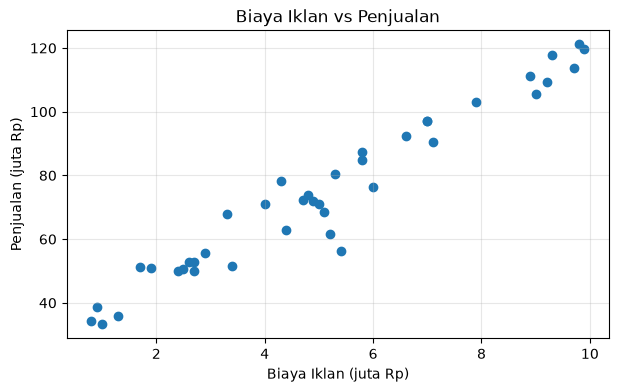

In [86]:
ads = pd.read_csv("Ads_Data.csv")
display(ads.head())
print("Jumlah baris data:", len(ads))
X = ads[["BiayaIklan"]].to_numpy()
y = ads["Penjualan"].to_numpy()
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(True, alpha=0.3)
plt.show()

## A2 – Split data
Bagi data dengan `test_size=0.2` dan `random_state=100`. Tampilkan shape setiap hasil pembagian.

In [87]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


## A3 – Training dengan normal equation
Latih model buatan sendiri, tampilkan intercept, koefisien, persamaan, dan interpretasi koefisien.

In [88]:
lin = LinearRegression().fit(X_train, y_train)
print(f"Intercept (b): {lin.intercept_:.4f}")
print(f"Koefisien (m): {lin.coef_[0]:.4f}")
print(f"Persamaan regresi: ŷ = {lin.intercept_:.4f} + ({lin.coef_[0]:.4f})X")
if lin.coef_[0] > 0:
    print(f"Interpretasi: kenaikan biaya iklan Rp1 juta berkaitan dengan kenaikan prediksi penjualan sekitar {lin.coef_[0]:.4f} juta Rp.")
elif lin.coef_[0] < 0:
    print(f"Interpretasi: kenaikan biaya iklan Rp1 juta berkaitan dengan penurunan prediksi penjualan sekitar {abs(lin.coef_[0]):.4f} juta Rp.")
else:
    print("Interpretasi: model tidak menunjukkan perubahan penjualan berdasarkan koefisien biaya iklan.")

Intercept (b): 28.4365
Koefisien (m): 9.1358
Persamaan regresi: ŷ = 28.4365 + (9.1358)X
Interpretasi: kenaikan biaya iklan Rp1 juta berkaitan dengan kenaikan prediksi penjualan sekitar 9.1358 juta Rp.


## A4 – Evaluasi model
Hitung MAE, MSE, RMSE, dan R² untuk training dan testing. Nilai RMSE menunjukkan besar kesalahan tipikal dalam satuan penjualan. R² yang mendekati 1 menunjukkan model menjelaskan variasi data dengan baik; bandingkan hasil testing untuk menilai kemampuan pada data yang tidak dilatih.

In [89]:
train_pred = lin.predict(X_train)
test_pred = lin.predict(X_test)
metric_rows = []
for nama, yt, yp in [("Training", y_train, train_pred), ("Testing", y_test, test_pred)]:
    metric_rows.append([nama, *regression_metrics(yt, yp)])
regression_results = pd.DataFrame(
    metric_rows, columns=["Data", "MAE", "MSE", "RMSE", "R²"]
)
display(regression_results.round(4))

,Data,MAE,MSE,RMSE,R²
0,Training,4.9002,42.2219,6.4978,0.9324
1,Testing,2.7510,11.8675,3.4449,0.9823


## A5 – Gradient Descent dan learning rate
Latih `LinearRegressionGD` selama 5000 iterasi dengan learning rate 0.001, 0.02, dan 0.1. Bandingkan parameter dengan normal equation dan periksa grafik loss.

LR=0.001: intercept=28.4385, koefisien=9.1354, loss akhir=0.067624
LR=0.02: intercept=28.4365, koefisien=9.1358, loss akhir=0.067624
LR=0.1: intercept=28.4365, koefisien=9.1358, loss akhir=0.067624
Normal equation: intercept=28.4365, koefisien=9.1358


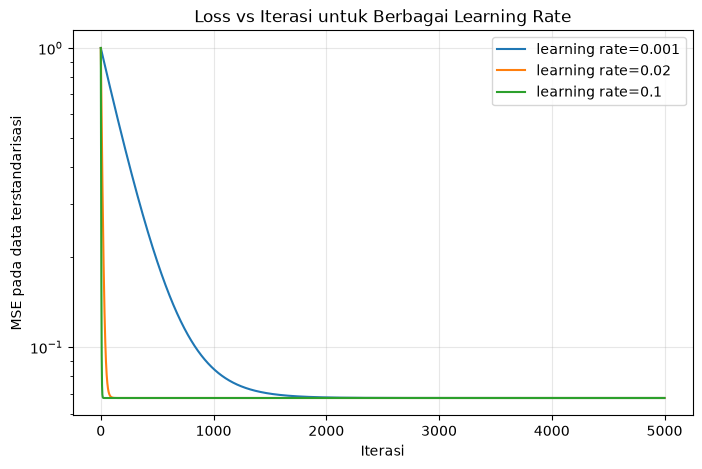

In [90]:
gd_models = {}
plt.figure(figsize=(8, 5))
for lr in [0.001, 0.02, 0.1]:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    print(f"LR={lr}: intercept={model.intercept_:.4f}, koefisien={model.coef_[0]:.4f}, loss akhir={model.loss_history[-1]:.6f}")
    plt.plot(model.loss_history, label=f"learning rate={lr}")
print(f"Normal equation: intercept={lin.intercept_:.4f}, koefisien={lin.coef_[0]:.4f}")
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE pada data terstandarisasi")
plt.title("Loss vs Iterasi untuk Berbagai Learning Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Analisis A5:** Learning rate kecil biasanya belajar lebih lambat. Learning rate yang sesuai menurunkan loss dan kemudian stabil. Learning rate terlalu besar dapat membuat loss berosilasi atau divergen. Gunakan grafik dan loss akhir di atas untuk menentukan hasil aktual setiap learning rate, bukan hanya berdasarkan dugaan.

## A6 – Visualisasi dan prediksi
Buat scatter plot data testing dengan garis regresi, lalu prediksi penjualan pada biaya iklan 4.5, 7, dan 12 juta. Prediksi 12 juta merupakan ekstrapolasi jika berada di luar rentang data, sehingga lebih tidak pasti.

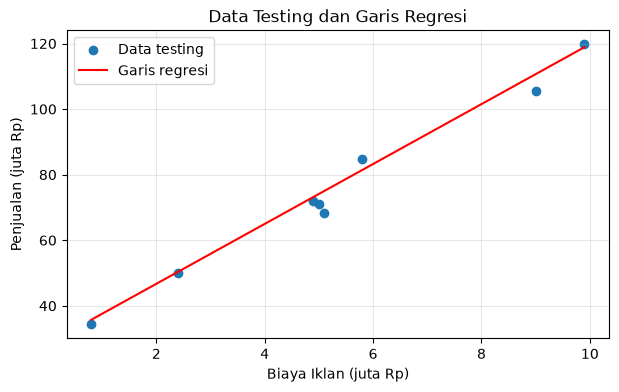

Biaya iklan 4.5 juta -> prediksi penjualan 69.5476 juta Rp
Biaya iklan 7 juta -> prediksi penjualan 92.3871 juta Rp
Biaya iklan 12 juta -> prediksi penjualan 138.0660 juta Rp
Rentang biaya iklan pada dataset: 0.8 sampai 9.9


In [91]:
plt.figure(figsize=(7, 4))
plt.scatter(X_test[:, 0], y_test, label="Data testing")
xline = np.linspace(X[:, 0].min(), X[:, 0].max(), 100).reshape(-1, 1)
plt.plot(xline[:, 0], lin.predict(xline), color="red", label="Garis regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.title("Data Testing dan Garis Regresi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

nilai_iklan = np.array([[4.5], [7.0], [12.0]])
for nilai, pred in zip(nilai_iklan[:, 0], lin.predict(nilai_iklan)):
    print(f"Biaya iklan {nilai:g} juta -> prediksi penjualan {pred:.4f} juta Rp")
print("Rentang biaya iklan pada dataset:", X[:, 0].min(), "sampai", X[:, 0].max())

**Analisis A6:** Prediksi di dalam rentang biaya iklan yang tersedia umumnya lebih dapat dipercaya karena masih dekat dengan data yang dipelajari. Prediksi 12 juta perlu lebih hati-hati jika berada di luar rentang data, karena hubungan biaya iklan dan penjualan belum tentu terus linear.

# Bagian B – Logistic Regression (40%)

Layanan email ingin membuat filter spam berdasarkan jumlah link dan jumlah kata promosi. Gunakan `Email_Data.csv`.

## B1 – Load dan visualisasi data
Tampilkan lima data pertama, jumlah spam dan bukan spam, lalu buat scatter plot.

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email Spam: 25
Jumlah email Bukan Spam: 35


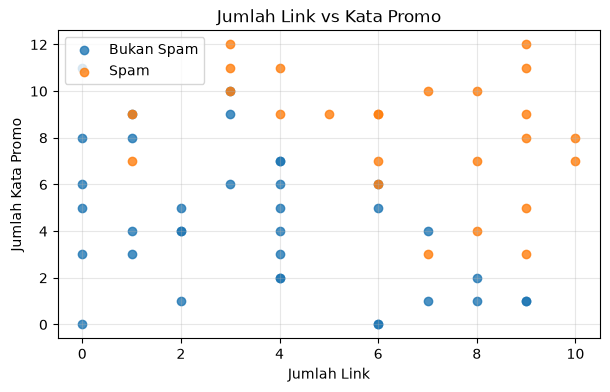

In [92]:
email = pd.read_csv("Email_Data.csv")
display(email.head())
print("Jumlah email Spam:", int((email["Spam"] == 1).sum()))
print("Jumlah email Bukan Spam:", int((email["Spam"] == 0).sum()))
X_email = email[["JumlahLink", "KataPromo"]].to_numpy()
y_email = email["Spam"].to_numpy()

plt.figure(figsize=(7, 4))
for label, nama in [(0, "Bukan Spam"), (1, "Spam")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], label=nama, alpha=0.8)
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Jumlah Link vs Kata Promo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## B2 – Split data dan training
Bagi data dengan `test_size=0.25`, latih Logistic Regression buatan sendiri dengan learning rate 0.1 dan 10000 iterasi, tampilkan parameter, persamaan probabilitas, dan grafik log loss.

Intercept (b): -13.747133
Koefisien: [1.20737043 1.13525543]
P(Spam) = sigmoid(-13.747133 + (1.207370)JumlahLink + (1.135255)KataPromo)


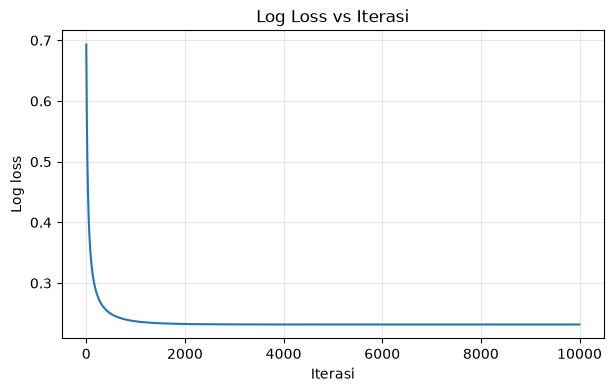

Loss awal: 0.693147
Loss akhir: 0.231741


In [93]:
Xtr, Xte, ytr, yte = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
logreg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xtr, ytr)
print(f"Intercept (b): {logreg.intercept_:.6f}")
print("Koefisien:", logreg.coef_)
print(
    f"P(Spam) = sigmoid({logreg.intercept_:.6f} "
    f"+ ({logreg.coef_[0]:.6f})JumlahLink "
    f"+ ({logreg.coef_[1]:.6f})KataPromo)"
)
plt.figure(figsize=(7, 4))
plt.plot(logreg.loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.title("Log Loss vs Iterasi")
plt.grid(True, alpha=0.3)
plt.show()
print("Loss awal:", round(logreg.loss_history[0], 6))
print("Loss akhir:", round(logreg.loss_history[-1], 6))

**Analisis B2:** Jika log loss menurun dan kemudian relatif stabil, model sedang belajar dan optimasi mulai konvergen. Koefisien positif menunjukkan bahwa kenaikan fitur tersebut meningkatkan kecenderungan prediksi spam, dengan fitur lain tetap.

## B3 – Evaluasi model
Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada data testing. FP adalah email bukan spam yang salah ditandai sebagai spam; FN adalah email spam yang lolos sebagai bukan spam.

In [94]:
y_pred = logreg.predict(Xte)
cm = confusion_matrix(yte, y_pred)
precision, recall, f1 = classification_metrics(yte, y_pred)
print("Accuracy:", round(accuracy_score(yte, y_pred), 4))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Accuracy: 0.8667
Confusion matrix [[TN, FP], [FN, TP]]:
[[9 1]
 [1 4]]
Precision: 0.8
Recall: 0.8
F1-score: 0.8


**Analisis B3:** FP berarti email penting yang bukan spam dapat masuk ke folder spam. FN berarti email spam masuk ke kotak masuk. FN dapat lebih merugikan jika spam berisi penipuan atau tautan berbahaya, tetapi FP juga berisiko karena pengguna bisa melewatkan email penting.

## B4 – Decision boundary
Visualisasikan probabilitas spam, data testing, garis decision boundary pada probabilitas 0.5, dan tandai data testing yang salah diklasifikasikan.

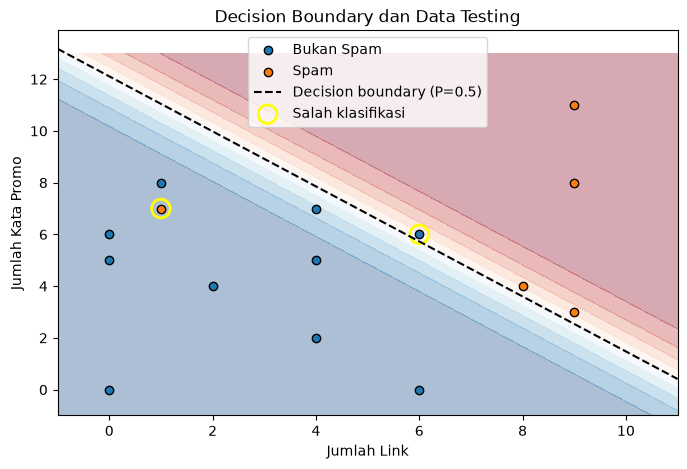

Posisi data testing yang salah diklasifikasikan: [ 9 12]
Label aktual untuk data yang salah: [0 1]
Prediksi untuk data yang salah: [1 0]


In [95]:
plt.figure(figsize=(8, 5))
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)
grid = np.c_[xx.ravel(), yy.ravel()]
probs = logreg.predict_proba(grid)[:, 1].reshape(xx.shape)
plt.contourf(xx, yy, probs, levels=np.linspace(0, 1, 11), alpha=0.35, cmap="RdBu_r")
for label, nama in [(0, "Bukan Spam"), (1, "Spam")]:
    mask = yte == label
    plt.scatter(Xte[mask, 0], Xte[mask, 1], label=nama, edgecolors="black")
if abs(logreg.coef_[1]) > 1e-12:
    x_vals = np.linspace(x1_min, x1_max, 200)
    y_vals = -(logreg.intercept_ + logreg.coef_[0] * x_vals) / logreg.coef_[1]
    plt.plot(x_vals, y_vals, "k--", label="Decision boundary (P=0.5)")
wrong = y_pred != yte
plt.scatter(Xte[wrong, 0], Xte[wrong, 1], s=180, facecolors="none",
            edgecolors="yellow", linewidths=2, label="Salah klasifikasi")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Decision Boundary dan Data Testing")
plt.legend()
plt.show()
print("Posisi data testing yang salah diklasifikasikan:", np.where(wrong)[0])
print("Label aktual untuk data yang salah:", yte[wrong])
print("Prediksi untuk data yang salah:", y_pred[wrong])

**Analisis B4:** Garis decision boundary menunjukkan batas probabilitas spam 0,5. Titik yang dilingkari kuning merupakan data testing yang prediksinya berbeda dari label aktual.

## B5 – Eksperimen threshold
Bandingkan threshold 0.3, 0.5, dan 0.7 menggunakan probabilitas pada data testing. Tampilkan confusion matrix, precision, dan recall.

In [96]:
threshold_rows = []
threshold_preds = {}
prob_test = logreg.predict_proba(Xte)[:, 1]
for th in [0.3, 0.5, 0.7]:
    pred = (prob_test >= th).astype(int)
    threshold_preds[th] = pred
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    p, r, f = classification_metrics(yte, pred)
    threshold_rows.append([th, tn, fp, fn, tp, p, r, f])
threshold_results = pd.DataFrame(
    threshold_rows,
    columns=["Threshold", "TN", "FP", "FN", "TP", "Precision", "Recall", "F1"]
)
display(threshold_results.round(4))

,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.3,9,1,1,4,0.8,0.8,0.8000
1,0.5,9,1,1,4,0.8,0.8,0.8000
2,0.7,10,0,3,2,1.0,0.4,0.5714


**Analisis B5:** Threshold lebih rendah cenderung menandai lebih banyak email sebagai spam sehingga recall dapat meningkat, tetapi FP juga dapat bertambah. Threshold lebih tinggi lebih selektif, tetapi dapat membuat spam lebih banyak lolos. Untuk mengurangi spam yang lolos ke inbox, threshold 0,3 dapat dipilih, dengan konsekuensi risiko FP lebih tinggi. Periksa tabel aktual untuk melihat dampaknya pada dataset ini.

## B6 – Prediksi email baru
Prediksi kelas dan probabilitas spam untuk E1–E4 dengan threshold pilihan 0,3.

In [97]:
threshold_pilihan = 0.3
email_baru = np.array([[1, 2], [5, 6], [9, 10], [2, 11]], dtype=float)
prob_spam = logreg.predict_proba(email_baru)[:, 1]
pred_spam = (prob_spam >= threshold_pilihan).astype(int)
hasil_email = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": email_baru[:, 0].astype(int),
    "KataPromo": email_baru[:, 1].astype(int),
    "Probabilitas Spam": prob_spam,
    "Prediksi": ["Spam" if p == 1 else "Bukan Spam" for p in pred_spam]
})
display(hasil_email.round(4))

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi
0,E1,1,2,0.0000,Bukan Spam
1,E2,5,6,0.2893,Bukan Spam
2,E3,9,10,0.9998,Spam
3,E4,2,11,0.7605,Spam


# Bagian C – Pemahaman Konsep (15%)

### C1. Mengapa Logistic Regression termasuk klasifikasi dan apa peran sigmoid?
Logistic Regression termasuk klasifikasi karena digunakan untuk memprediksi kelas, misalnya spam atau bukan spam. Fungsi sigmoid mengubah hasil perhitungan model menjadi probabilitas antara 0 dan 1. Probabilitas tersebut dibandingkan dengan threshold untuk menentukan kelas.

### C2. Perbedaan normal equation dan gradient descent
Normal equation menghitung koefisien secara langsung melalui operasi matriks tanpa iterasi. Gradient descent memperbarui koefisien secara bertahap berdasarkan gradien loss. Gradient descent lebih berguna untuk dataset besar atau ketika penyelesaian langsung melalui matriks menjadi berat.

### C3. Mengapa evaluasi menggunakan data testing dan apa itu overfitting?
Data testing mengukur kemampuan model pada data yang tidak digunakan saat training. Evaluasi hanya pada data training bisa memberikan gambaran yang terlalu optimistis. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training sehingga kinerjanya menurun pada data baru.

### C4. Mengapa Linear Regression memakai MSE dan Logistic Regression memakai log loss?
Linear Regression menghasilkan nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih prediksi dan nilai sebenarnya. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss mengukur kesesuaian probabilitas dengan label sebenarnya. Log loss memberi penalti besar jika model sangat yakin tetapi prediksinya salah.

### C5. Mengapa hasil dapat berbeda dengan teman?
Hasil dapat berbeda jika pembagian data training dan testing atau random state berbeda. Pengaturan learning rate, jumlah iterasi, inisialisasi parameter, dan standardisasi juga memengaruhi hasil. Karena itu, eksperimen harus memakai pengaturan yang konsisten agar hasil bisa dibandingkan secara adil.

# Bonus (+5) – Perbandingan dengan scikit-learn

Bagian ini satu-satunya bagian yang menggunakan scikit-learn. Model dilatih pada pembagian data yang sama, lalu koefisien dan metrik dibandingkan dengan implementasi NumPy.

In [98]:
try:
    from sklearn.linear_model import LinearRegression as SKLinearRegression
    from sklearn.linear_model import LogisticRegression as SKLogisticRegression
    from sklearn.metrics import (
        mean_absolute_error as sk_mae,
        mean_squared_error as sk_mse,
        r2_score as sk_r2,
        accuracy_score as sk_accuracy,
        confusion_matrix as sk_cm
    )

    sk_lin = SKLinearRegression().fit(X_train, y_train)
    own_lin_pred = lin.predict(X_test)
    sk_lin_pred = sk_lin.predict(X_test)
    print("Linear Regression — implementasi NumPy")
    print("Intercept:", lin.intercept_, "| Koefisien:", lin.coef_)
    print("Linear Regression — scikit-learn")
    print("Intercept:", sk_lin.intercept_, "| Koefisien:", sk_lin.coef_)
    print("R² testing NumPy:", regression_metrics(y_test, own_lin_pred)[3])
    print("R² testing scikit-learn:", sk_r2(y_test, sk_lin_pred))

    sk_log = SKLogisticRegression(max_iter=10000).fit(Xtr, ytr)
    sk_pred = sk_log.predict(Xte)
    print("\nLogistic Regression — implementasi NumPy")
    print("Intercept:", logreg.intercept_, "| Koefisien:", logreg.coef_)
    print("Accuracy:", accuracy_score(yte, logreg.predict(Xte)))
    print("Logistic Regression — scikit-learn")
    print("Intercept:", sk_log.intercept_, "| Koefisien:", sk_log.coef_)
    print("Accuracy:", sk_accuracy(yte, sk_pred))
    print("Confusion matrix scikit-learn:")
    print(sk_cm(yte, sk_pred))
except ImportError:
    print("scikit-learn belum tersedia; bagian bonus dilewati.")

Linear Regression — implementasi NumPy
Intercept: 28.436494904252616 | Koefisien: [9.13579512]
Linear Regression — scikit-learn
Intercept: 28.43649490425259 | Koefisien: [9.13579512]
R² testing NumPy: 0.9823382760914564
R² testing scikit-learn: 0.9823382760914562

Logistic Regression — implementasi NumPy
Intercept: -13.747132651823392 | Koefisien: [1.20737043 1.13525543]
Accuracy: 0.8666666666666667
Logistic Regression — scikit-learn
Intercept: [-11.15918064] | Koefisien: [[0.95311741 0.93513906]]
Accuracy: 0.8666666666666667
Confusion matrix scikit-learn:
[[9 1]
 [1 4]]


**Analisis bonus:** Hasil Linear Regression umumnya serupa karena keduanya mencari koefisien yang meminimalkan kuadrat error. Hasil Logistic Regression dapat berbeda karena metode optimasi dan regularisasi bawaan scikit-learn berbeda dari implementasi NumPy sederhana yang tidak menggunakan regularisasi.